# H-E10: H-N00 + H-N30 probability ensemble

H-N00(전체 Macro Dice 우수)과 H-N30(Recall/탐지율 우수)의 validation softmax probability를 가중 평균합니다.

- validation 40건 확률 생성
- H-N00 weight 0.5~1.0
- probability threshold 0.30~0.70
- 양성·작은 병변·음성 성능 비교
- H-N00 단독 재현 검사
- 안전 조건 기반 후보 추천

주의: 같은 validation에서 weight와 threshold를 선택한 탐색 결과이므로 최종 성능은 별도 fold에서 재검증해야 합니다.

In [1]:
from pathlib import Path
import json, subprocess
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
from IPython.display import display

ROOT=Path("/home/stu03/workspace/model")
PYTHON=ROOT/".venv/bin/python"
DATA_ROOT=ROOT.parent/"datasets/hemorrhage/v1/model_ready/nnunet"
DATASET="Dataset001_ICHBinary"
SPLIT=DATA_ROOT/"nnUNet_preprocessed"/DATASET/"splits_final.json"
GT_DIR=DATA_ROOT/"nnUNet_preprocessed"/DATASET/"gt_segmentations"
PROB_ROOT=ROOT/"runs/ensembles/H-E10/probabilities"
OUTPUT_DIR=ROOT/"runs/ensembles/H-E10"; OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
CASES=json.loads(SPLIT.read_text(encoding="utf-8"))[0]["val"]
WEIGHTS_N00=[0.5,0.6,0.7,0.8,0.9,1.0]
THRESHOLDS=np.round(np.arange(0.30,0.701,0.05),2).tolist()
print(len(CASES),WEIGHTS_N00,THRESHOLDS)

40 [0.5, 0.6, 0.7, 0.8, 0.9, 1.0] [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7]


## 1. Softmax probability 생성

이미 생성된 case는 자동으로 건너뜁니다. 두 모델 합계 약 80건의 full-volume 추론이며 GPU를 사용합니다.

In [2]:
command=[str(PYTHON),"scripts/validation/export_h_e10_probabilities.py"]
subprocess.run(command,cwd=ROOT,check=True)
for experiment in ["H-N00","H-N30"]:
    files=list((PROB_ROOT/experiment).glob("*.npz"))
    print(experiment,len(files))
    assert len(files)==len(CASES)

===== H-N00: probability export =====
cases=40, export=0, skip=40
===== H-N30: probability export =====
cases=40, export=0, skip=40
H-N00 40
H-N30 40


## 2. Probability/GT shape 및 채널 확인

In [3]:
for case in CASES[:3]:
    p00=np.load(PROB_ROOT/"H-N00"/f"{case}.npz")["probabilities"]
    p30=np.load(PROB_ROOT/"H-N30"/f"{case}.npz")["probabilities"]
    gt=np.asarray(nib.load(GT_DIR/f"{case}.nii.gz").dataobj).transpose(2,1,0)
    print(case,p00.shape,p30.shape,gt.shape,float(p00.min()),float(p00.max()))
    assert p00.shape==p30.shape and p00.shape[0]==2 and p00.shape[1:]==gt.shape
    np.testing.assert_allclose(p00.sum(axis=0),1,atol=2e-3)

BHSD_ID_02b882cc_ID_a4892e60ae (2, 32, 512, 512) (2, 32, 512, 512) (32, 512, 512) 6.324127483201324e-22 1.0
BHSD_ID_07365cde_ID_8e661b8f07 (2, 30, 512, 512) (2, 30, 512, 512) (30, 512, 512) 1.7164902439270304e-18 1.0
BHSD_ID_0b10cbee_ID_f91d6a7cd2 (2, 32, 512, 512) (2, 32, 512, 512) (32, 512, 512) 4.254754134166733e-21 1.0


## 3. 54개 weight × threshold 조합의 case별 metric 계산

In [4]:
def segmentation_metrics(gt,pred):
    gt,pred=np.asarray(gt,bool),np.asarray(pred,bool)
    tp=int((gt&pred).sum()); fp=int((~gt&pred).sum()); fn=int((gt&~pred).sum())
    denom=2*tp+fp+fn
    return tp,fp,fn,2*tp/denom if denom else np.nan,tp/(tp+fn) if tp+fn else np.nan,tp/(tp+fp) if tp+fp else np.nan

rows=[]
for number,case in enumerate(CASES,1):
    img=nib.load(GT_DIR/f"{case}.nii.gz"); gt=np.asarray(img.dataobj).transpose(2,1,0)>0
    voxel_ml=float(np.prod(img.header.get_zooms()[:3]))/1000; gt_ml=float(gt.sum())*voxel_ml; positive=bool(gt.any())
    group="negative" if not positive else "<1 mL" if gt_ml<1 else "1–5 mL" if gt_ml<5 else "5–20 mL" if gt_ml<20 else "≥20 mL"
    p00=np.load(PROB_ROOT/"H-N00"/f"{case}.npz")["probabilities"][1].astype(np.float32)
    p30=np.load(PROB_ROOT/"H-N30"/f"{case}.npz")["probabilities"][1].astype(np.float32)
    for weight in WEIGHTS_N00:
        ensemble=weight*p00+(1-weight)*p30
        for threshold in THRESHOLDS:
            pred=ensemble>threshold
            tp,fp,fn,dice,recall,precision=segmentation_metrics(gt,pred)
            rows.append({"case_id":case,"source":"PhysioNet" if case.startswith("PHYS_") else "BHSD","positive":positive,"gt_volume_ml":gt_ml,"volume_group":group,"weight_n00":weight,"weight_n30":1-weight,"threshold":threshold,"dice":dice,"recall":recall,"precision":precision,"tp":tp,"fp":fp,"fn":fn,"predicted_voxels":int(pred.sum()),"overlap_detected":tp>0,"predicted_positive":bool(pred.any())})
    if number%10==0: print(f"{number}/{len(CASES)}")
per_case=pd.DataFrame(rows); print(per_case.shape); display(per_case.head())

10/40
20/40
30/40
40/40
(2160, 17)


,case_id,source,positive,gt_volume_ml,volume_group,weight_n00,weight_n30,threshold,dice,recall,precision,tp,fp,fn,predicted_voxels,overlap_detected,predicted_positive
0,BHSD_ID_02b882cc_ID_a4892e60ae,BHSD,True,105.491404,≥20 mL,0.5,0.5,0.30,0.853971,0.935758,0.785332,76778,20987,5271,97765,True,True
1,BHSD_ID_02b882cc_ID_a4892e60ae,BHSD,True,105.491404,≥20 mL,0.5,0.5,0.35,0.860330,0.930542,0.799971,76350,19091,5699,95441,True,True
2,BHSD_ID_02b882cc_ID_a4892e60ae,BHSD,True,105.491404,≥20 mL,0.5,0.5,0.40,0.866252,0.924399,0.814988,75846,17218,6203,93064,True,True
3,BHSD_ID_02b882cc_ID_a4892e60ae,BHSD,True,105.491404,≥20 mL,0.5,0.5,0.45,0.871004,0.917415,0.829062,75273,15520,6776,90793,True,True
4,BHSD_ID_02b882cc_ID_a4892e60ae,BHSD,True,105.491404,≥20 mL,0.5,0.5,0.50,0.876262,0.911212,0.843895,74764,13830,7285,88594,True,True


## 4. H-N00 단독 재현 검사

In [5]:
baseline=per_case[(per_case.weight_n00==1.0)&(per_case.threshold==0.5)]
pos=baseline[baseline.positive]
reproduced={"macro_dice":pos.dice.mean(),"recall":pos.recall.mean(),"precision":pos.precision.mean(),"detection":pos.overlap_detected.mean(),"zero_dice":int((pos.dice==0).sum())}
expected={"macro_dice":0.594572,"recall":0.621163,"precision":0.606839,"detection":0.914286,"zero_dice":3}
print("reproduced",reproduced); print("expected",expected)
assert abs(reproduced["macro_dice"]-expected["macro_dice"])<0.002, "H-N00 재현 실패: probability 처리 확인 필요"

reproduced {'macro_dice': np.float64(0.5945732124911556), 'recall': np.float64(0.6211635185834757), 'precision': np.float64(0.6068412826647167), 'detection': np.float64(0.9142857142857143), 'zero_dice': 3}
expected {'macro_dice': 0.594572, 'recall': 0.621163, 'precision': 0.606839, 'detection': 0.914286, 'zero_dice': 3}


## 5. 설정별 전체·작은 병변·음성 요약

In [6]:
rows=[]
for (weight,threshold),current in per_case.groupby(["weight_n00","threshold"]):
    positive=current[current.positive]; negative=current[~current.positive]; small=positive[positive.gt_volume_ml<5]
    rows.append({"weight_n00":weight,"weight_n30":1-weight,"threshold":threshold,"macro_dice_positive":positive.dice.mean(),"macro_recall_positive":positive.recall.mean(),"macro_precision_positive":positive.precision.mean(),"detection_positive":positive.overlap_detected.mean(),"zero_dice_positive":int((positive.dice==0).sum()),"dice_under_5ml":small.dice.mean(),"recall_under_5ml":small.recall.mean(),"precision_under_5ml":small.precision.mean(),"detection_under_5ml":small.overlap_detected.mean(),"zero_dice_under_5ml":int((small.dice==0).sum()),"case_specificity":(~negative.predicted_positive).mean(),"true_negative_cases":int((~negative.predicted_positive).sum()),"mean_fp_voxels_negative":negative.fp.mean()})
summary=pd.DataFrame(rows)
display(summary.sort_values("macro_dice_positive",ascending=False).head(15).style.format({c:"{:.4f}" for c in summary.select_dtypes('number').columns}).background_gradient(subset=["macro_dice_positive","detection_positive","dice_under_5ml","case_specificity"],cmap="YlGn"))

,weight_n00,weight_n30,threshold,macro_dice_positive,macro_recall_positive,macro_precision_positive,detection_positive,zero_dice_positive,dice_under_5ml,recall_under_5ml,precision_under_5ml,detection_under_5ml,zero_dice_under_5ml,case_specificity,true_negative_cases,mean_fp_voxels_negative
8,0.5000,0.5000,0.7000,0.6001,0.6106,0.6231,0.9143,3.0000,0.3511,0.4380,0.3284,0.7273,3.0000,0.0000,0.0000,1526.8000
17,0.6000,0.4000,0.7000,0.5999,0.6090,0.6257,0.9143,3.0000,0.3528,0.4397,0.3322,0.7273,3.0000,0.0000,0.0000,1493.4000
16,0.6000,0.4000,0.6500,0.5998,0.6147,0.6203,0.9143,3.0000,0.3510,0.4465,0.3266,0.7273,3.0000,0.0000,0.0000,1591.2000
7,0.5000,0.5000,0.6500,0.5997,0.6161,0.6167,0.9143,3.0000,0.3482,0.4431,0.3210,0.7273,3.0000,0.0000,0.0000,1631.4000
6,0.5000,0.5000,0.6000,0.5996,0.6228,0.6108,0.9143,3.0000,0.3460,0.4512,0.3145,0.7273,3.0000,0.0000,0.0000,1758.6000
26,0.7000,0.3000,0.7000,0.5994,0.6097,0.6265,0.9143,3.0000,0.3536,0.4462,0.3339,0.7273,3.0000,0.0000,0.0000,1507.4000
15,0.6000,0.4000,0.6000,0.5992,0.6211,0.6139,0.9143,3.0000,0.3483,0.4557,0.3195,0.7273,3.0000,0.0000,0.0000,1712.0000
5,0.5000,0.5000,0.5500,0.5990,0.6299,0.6032,0.9143,3.0000,0.3424,0.4583,0.3061,0.7273,3.0000,0.0000,0.0000,1929.6000
25,0.7000,0.3000,0.6500,0.5985,0.6149,0.6193,0.9143,3.0000,0.3508,0.4517,0.3277,0.7273,3.0000,0.0000,0.0000,1705.0000
14,0.6000,0.4000,0.5500,0.5978,0.6259,0.6063,0.9143,3.0000,0.3444,0.4593,0.3121,0.7273,3.0000,0.0000,0.0000,1933.8000


## 6. 안전 조건으로 후보 선택

In [7]:
BASE_DETECTION=0.914286; BASE_SMALL_DETECTION=0.727273
candidates=summary[(summary.detection_positive>=BASE_DETECTION-1e-6)&(summary.detection_under_5ml>=BASE_SMALL_DETECTION-1e-6)&(summary.zero_dice_positive<=3)].copy()
if len(candidates):
    ranked=candidates.sort_values(["macro_dice_positive","macro_recall_positive","case_specificity"],ascending=False)
    best=ranked.iloc[0]
    display(ranked.head(15).style.format({c:"{:.4f}" for c in ranked.select_dtypes('number').columns}).background_gradient(subset=["macro_dice_positive","macro_recall_positive","dice_under_5ml","case_specificity"],cmap="YlGn"))
    print("BEST",best.to_dict())
else:
    best=None; print("안전 조건을 만족하는 ensemble 없음")

,weight_n00,weight_n30,threshold,macro_dice_positive,macro_recall_positive,macro_precision_positive,detection_positive,zero_dice_positive,dice_under_5ml,recall_under_5ml,precision_under_5ml,detection_under_5ml,zero_dice_under_5ml,case_specificity,true_negative_cases,mean_fp_voxels_negative
8,0.5000,0.5000,0.7000,0.6001,0.6106,0.6231,0.9143,3.0000,0.3511,0.4380,0.3284,0.7273,3.0000,0.0000,0.0000,1526.8000
17,0.6000,0.4000,0.7000,0.5999,0.6090,0.6257,0.9143,3.0000,0.3528,0.4397,0.3322,0.7273,3.0000,0.0000,0.0000,1493.4000
16,0.6000,0.4000,0.6500,0.5998,0.6147,0.6203,0.9143,3.0000,0.3510,0.4465,0.3266,0.7273,3.0000,0.0000,0.0000,1591.2000
7,0.5000,0.5000,0.6500,0.5997,0.6161,0.6167,0.9143,3.0000,0.3482,0.4431,0.3210,0.7273,3.0000,0.0000,0.0000,1631.4000
6,0.5000,0.5000,0.6000,0.5996,0.6228,0.6108,0.9143,3.0000,0.3460,0.4512,0.3145,0.7273,3.0000,0.0000,0.0000,1758.6000
26,0.7000,0.3000,0.7000,0.5994,0.6097,0.6265,0.9143,3.0000,0.3536,0.4462,0.3339,0.7273,3.0000,0.0000,0.0000,1507.4000
15,0.6000,0.4000,0.6000,0.5992,0.6211,0.6139,0.9143,3.0000,0.3483,0.4557,0.3195,0.7273,3.0000,0.0000,0.0000,1712.0000
5,0.5000,0.5000,0.5500,0.5990,0.6299,0.6032,0.9143,3.0000,0.3424,0.4583,0.3061,0.7273,3.0000,0.0000,0.0000,1929.6000
25,0.7000,0.3000,0.6500,0.5985,0.6149,0.6193,0.9143,3.0000,0.3508,0.4517,0.3277,0.7273,3.0000,0.0000,0.0000,1705.0000
14,0.6000,0.4000,0.5500,0.5978,0.6259,0.6063,0.9143,3.0000,0.3444,0.4593,0.3121,0.7273,3.0000,0.0000,0.0000,1933.8000


BEST {'weight_n00': 0.5, 'weight_n30': 0.5, 'threshold': 0.7, 'macro_dice_positive': 0.6000729482353742, 'macro_recall_positive': 0.6106071550697015, 'macro_precision_positive': 0.6230833143398135, 'detection_positive': 0.9142857142857143, 'zero_dice_positive': 3.0, 'dice_under_5ml': 0.35111256972257426, 'recall_under_5ml': 0.43798350663806185, 'precision_under_5ml': 0.3283500503620063, 'detection_under_5ml': 0.7272727272727273, 'zero_dice_under_5ml': 3.0, 'case_specificity': 0.0, 'true_negative_cases': 0.0, 'mean_fp_voxels_negative': 1526.8}


## 7. Heatmap과 핵심 PhysioNet 사례

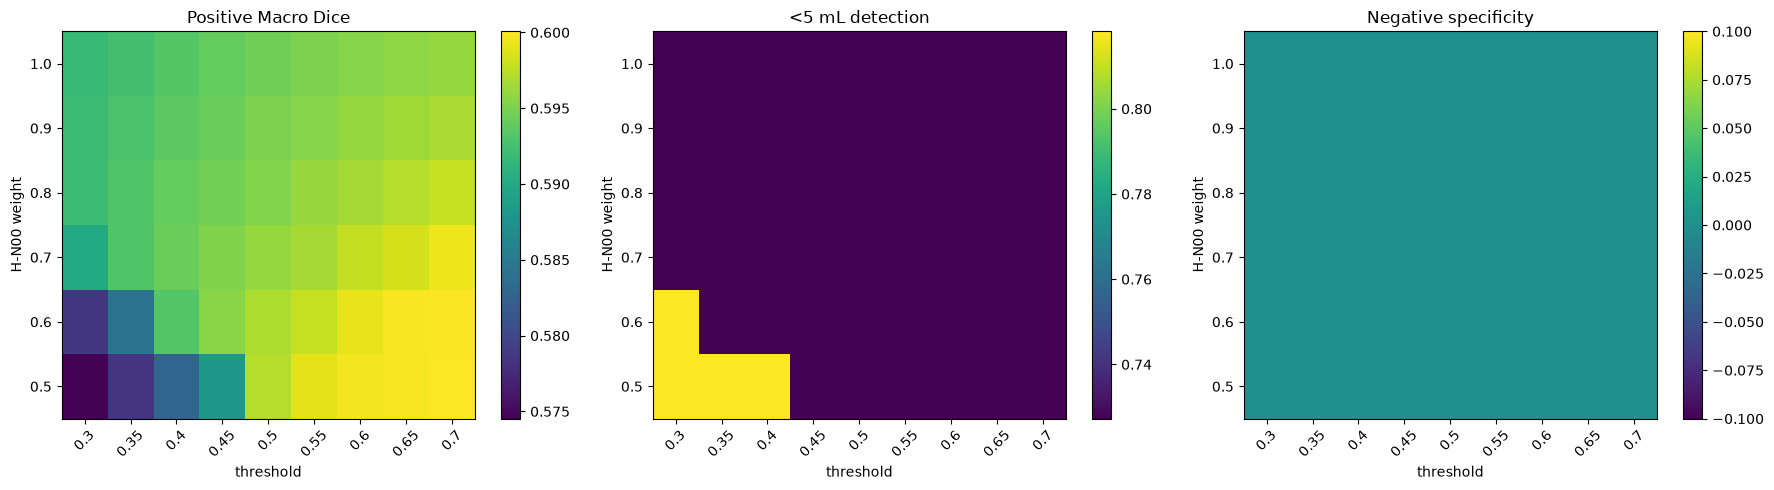

,case_id,gt_volume_ml,dice,recall,precision,tp,fp,fn,overlap_detected
1844,PHYS_58,0.252899,0.000000,0.000000,0.000000,0,455,279,False
2006,PHYS_78,5.720863,0.148109,0.125278,0.181116,844,3816,5893,True
2060,PHYS_82,1.694899,0.000000,0.000000,0.000000,0,106,2015,False


In [8]:
fig,axes=plt.subplots(1,3,figsize=(18,5))
for ax,metric,title in zip(axes,["macro_dice_positive","detection_under_5ml","case_specificity"],["Positive Macro Dice","<5 mL detection","Negative specificity"]):
    table=summary.pivot(index="weight_n00",columns="threshold",values=metric)
    image=ax.imshow(table.values,aspect="auto",origin="lower",cmap="viridis")
    ax.set_xticks(range(len(table.columns)),table.columns,rotation=45); ax.set_yticks(range(len(table.index)),table.index); ax.set(xlabel="threshold",ylabel="H-N00 weight",title=title); fig.colorbar(image,ax=ax)
fig.tight_layout(); fig.savefig(OUTPUT_DIR/"ensemble_heatmaps.png",dpi=170); plt.show()
if best is not None:
    selected=per_case[(per_case.weight_n00==best.weight_n00)&(per_case.threshold==best.threshold)]
    display(selected[selected.case_id.isin(["PHYS_58","PHYS_78","PHYS_82"])][["case_id","gt_volume_ml","dice","recall","precision","tp","fp","fn","overlap_detected"]])

## 8. 결과 저장

In [9]:
per_case.to_csv(OUTPUT_DIR/"ensemble_per_case.csv",index=False); summary.to_csv(OUTPUT_DIR/"ensemble_summary.csv",index=False)
if best is not None:
    payload={k:(int(v) if isinstance(v,(np.integer,)) else float(v) if isinstance(v,(np.floating,)) else v) for k,v in best.to_dict().items()}
    (OUTPUT_DIR/"best_setting.json").write_text(json.dumps(payload,ensure_ascii=False,indent=2),encoding="utf-8")
print("saved:",OUTPUT_DIR)

saved: /home/stu03/workspace/model/runs/ensembles/H-E10
